In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_df = pd.read_csv("../data/training.csv")
test_df = pd.read_csv("../data/testing.csv")

In [9]:
train_df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [10]:
train_df["Churn"].value_counts()

Churn
1.0    249999
0.0    190833
Name: count, dtype: int64

In [11]:
train_df["Churn"].value_counts(normalize=True) * 100

Churn
1.0    56.71072
0.0    43.28928
Name: proportion, dtype: float64

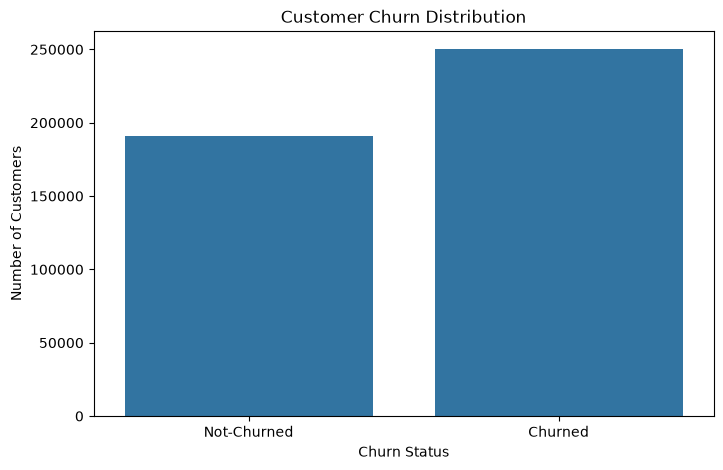

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=train_df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.xticks([0, 1], ["Not-Churned", "Churned"])

plt.show()

In [15]:
numerical_columns = train_df.select_dtypes(include=["int64", "float64"]).columns

print(numerical_columns)

Index(['CustomerID', 'Age', 'Tenure', 'Usage Frequency', 'Support Calls',
       'Payment Delay', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='str')


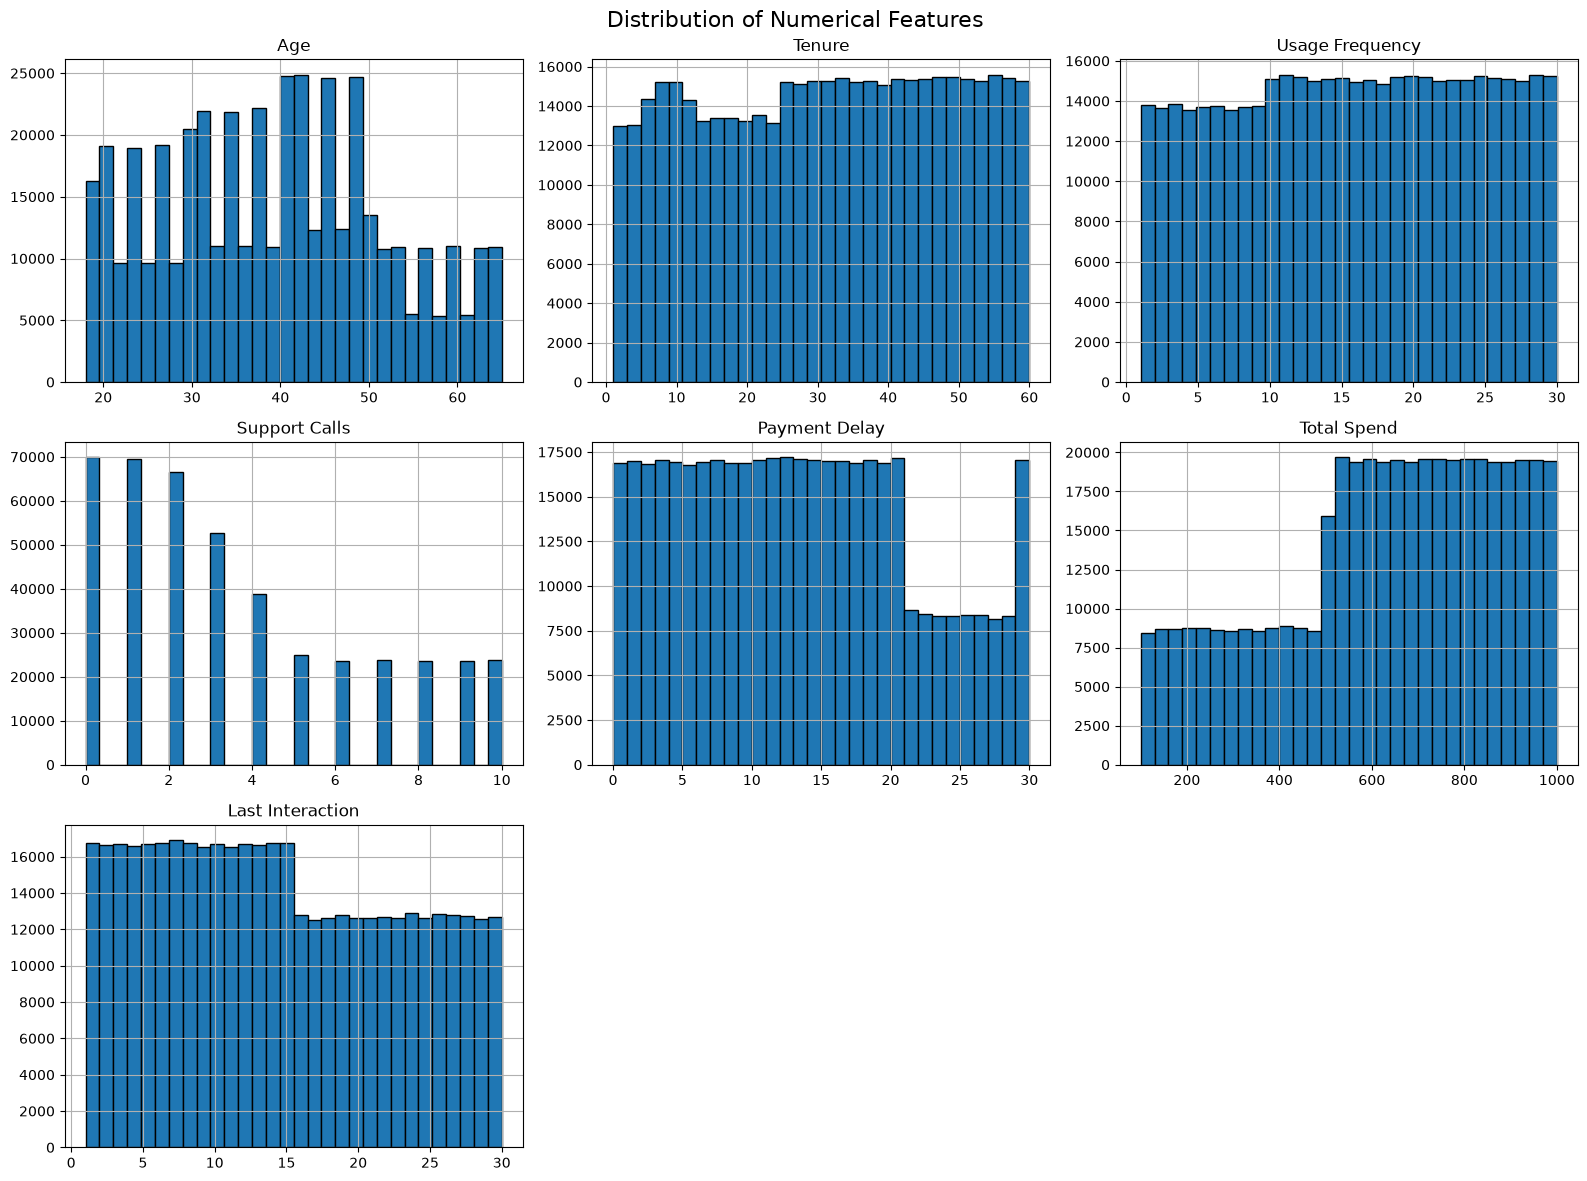

In [16]:
numerical_features = [
    col for col in numerical_columns
    if col not in ["CustomerID", "Churn"]
]

train_df[numerical_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)

plt.tight_layout()
plt.show()

In [18]:
categorical_columns = train_df.select_dtypes(
    include=["str", "category"]
).columns

print(categorical_columns)

Index(['Gender', 'Subscription Type', 'Contract Length'], dtype='str')


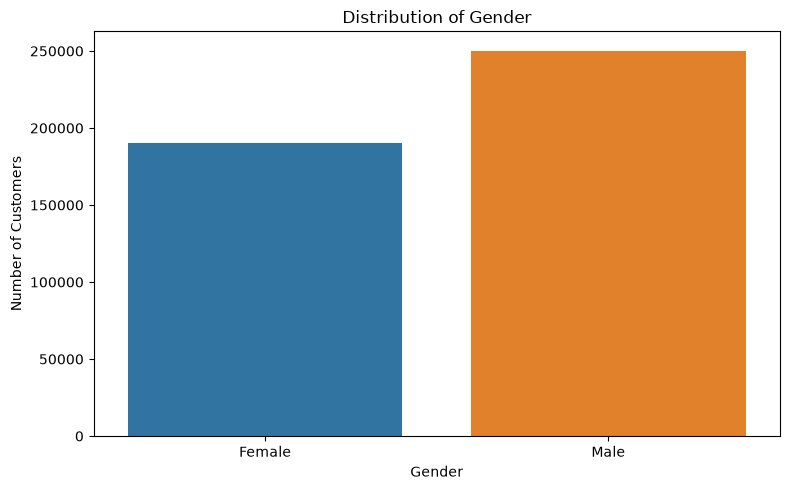

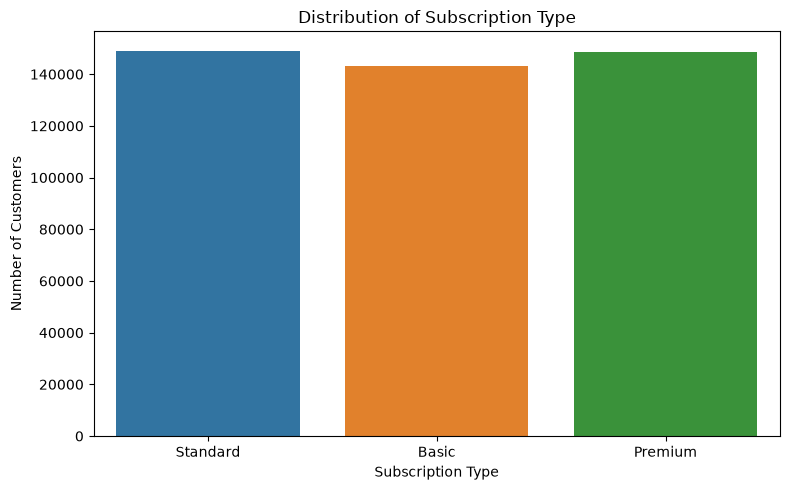

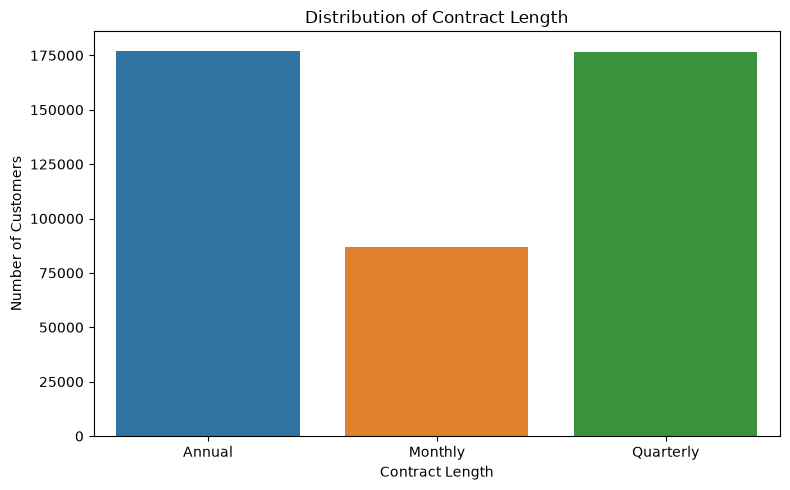

In [19]:
for col in categorical_columns:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=train_df,
        x=col,
        hue=col,
        legend=False
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")

    plt.tight_layout()
    plt.show()